# Customer churn: survival, lifetime value and who gets the offer

This notebook tells the story; the work is done by the `churn` package in `src/`. Run `make run` first so `data/` and `results/` exist.

In [1]:
import json, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
from IPython.display import Image, display

from churn.config import load_config, resolve
from churn.features import FEATURES
from churn.survival import CoxModel, km_table

cfg = load_config()
table = pd.read_parquet(resolve(cfg['data']['table']))
m = json.loads((resolve(cfg['paths']['results']) / 'metrics.json').read_text())
table.shape

(7032, 32)

## 1. The data after validation and cleaning

Every customer has a tenure (months) and a churn flag. Active customers are censored: we know they lasted at least this long.

In [2]:
pd.DataFrame(m['data']['cleaning'])

,step,rows_before,changed,dropped,rows_after
0,"drop customers with tenure 0 (signed up, no mo...",7043,0,11,7032
1,flag TotalCharges more than 35% away from tenu...,7032,6,0,7032
2,identical profiles under different ids (kept: ...,7032,22,0,7032


In [3]:
table.groupby('contract').agg(customers=('event', 'size'), churned=('event', 'sum'), mean_tenure=('tenure', 'mean')).round(1)

,customers,churned,mean_tenure
contract,,,
Month-to-month,3875,1655,18.0
One year,1472,166,42.1
Two year,1685,48,57.1


## 2. Who leaves, and when

Kaplan-Meier curves by contract. The log-rank test asks whether the curves could be the same.

In [4]:
km = km_table(table, 'contract', np.array([12, 24, 48, 72]))
print(f"log-rank chi2 = {km['logrank_statistic']:.0f}, p = {km['logrank_p']:.2g}")
pd.DataFrame({k: v['at'] for k, v in km['curves'].items()}).round(3)

log-rank chi2 = 2353, p = 0


,Month-to-month,One year,Two year
12,0.703,0.991,1.000
24,0.586,0.978,1.000
48,0.397,0.917,0.996
72,0.129,0.568,0.936


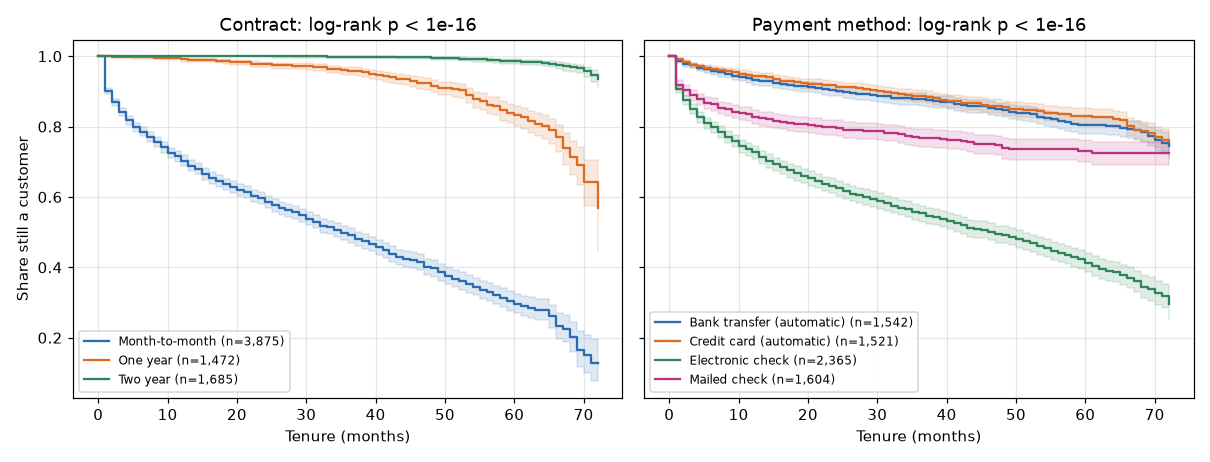

In [5]:
display(Image(str(ROOT / 'results' / 'km_curves.png')))

## 3. Models on the hold-out customers

C-index ranks time to churn on every hold-out customer; the 12-month metrics use only customers whose 12-month outcome is known.

In [6]:
pd.DataFrame(m['models']).T[['cindex', 'auc', 'brier', 'ece']].round(4)

,cindex,auc,brier,ece
km_contract,0.76811,0.79931,0.115556,0.024332
cox,0.855185,0.895206,0.096429,0.028383
cox_stratified,0.855501,0.895783,0.095922,0.019834
aft,0.855571,0.899512,0.094169,0.025669
xgboost_12m,0.856563,0.906161,0.091092,0.011689


## 4. Proportional hazards and hazard ratios

The plain Cox model fails the Schoenfeld test for the contract terms, so the final Cox model is stratified by contract.

In [7]:
print('fails PH (plain):', m['fit']['ph_failing'])
print('fails PH (stratified):', m['fit']['ph_failing_stratified'])
cox = CoxModel(FEATURES, m['fit']['cox_penalizer'], cfg['models']['cox']['strata']).fit(table)
cox.hazard_ratios().sort_values('hr').round(3)

fails PH (plain): ['contract_one_year', 'multiple_lines', 'online_security', 'pay_mailed_check', 'streaming_movies', 'streaming_tv', 'tech_support']
fails PH (stratified): ['multiple_lines', 'online_security', 'streaming_movies', 'streaming_tv', 'tech_support']


,feature,hr,lo,hi,p
7,online_security,0.530,0.465,0.603,0.000
8,online_backup,0.534,0.480,0.594,0.000
1,partner,0.609,0.547,0.679,0.000
4,multiple_lines,0.638,0.575,0.709,0.000
10,tech_support,0.666,0.586,0.757,0.000
9,device_protection,0.741,0.666,0.825,0.000
12,streaming_movies,0.895,0.804,0.996,0.042
16,pay_credit_card,0.914,0.766,1.090,0.318
2,dependents,0.936,0.818,1.070,0.331
0,senior,0.942,0.843,1.052,0.289


## 5. Lifetime value per active customer

From the log-normal AFT model: P(still paying k months from now) = S(t+k)/S(t), times margin, discounted.

In [8]:
values = pd.read_csv(resolve(cfg['data']['values']))
values[['p_churn_12m', 'expected_months', 'clv', 'clv_if_kept', 'gain']].describe().round(2)

,p_churn_12m,expected_months,clv,clv_if_kept,gain
count,5163.00,5163.00,5163.00,5163.00,5163.00
mean,0.12,47.93,1075.82,1171.94,-37.28
std,0.14,11.72,642.90,636.77,36.12
min,0.00,13.09,161.22,289.32,-117.69
25%,0.01,39.34,437.69,514.42,-66.41
50%,0.05,53.13,1000.29,1162.29,-26.15
75%,0.18,57.84,1599.37,1695.27,-12.91
max,0.67,59.93,2527.98,2532.23,64.84


In [9]:
pd.DataFrame(m['clv']['by_contract']).round(2)

,contract,customers,mean_clv,mean_months,mean_p12,value_plan,risk_plan
0,Month-to-month,2220,850.74,36.63,0.24,670,913
1,One year,1306,1232.52,54.41,0.04,0,0
2,Two year,1637,1256.04,58.09,0.01,0,0


## 6. Who gets the offer

Knapsack on expected gain against offering to the highest churn risks until the budget runs out.

In [10]:
t = m['targeting']
pd.DataFrame({'value plan': t['value_plan'], 'risk plan': t['risk_plan']}).round(3)

,value plan,risk plan
customers,670.000,913.000
spend,35803.900,49983.100
net_gain,10001.329,9006.232
expected_saves,67.161,83.421
mean_p_churn,0.401,0.365
mean_clv,503.961,561.624
month_to_month_share,1.000,1.000


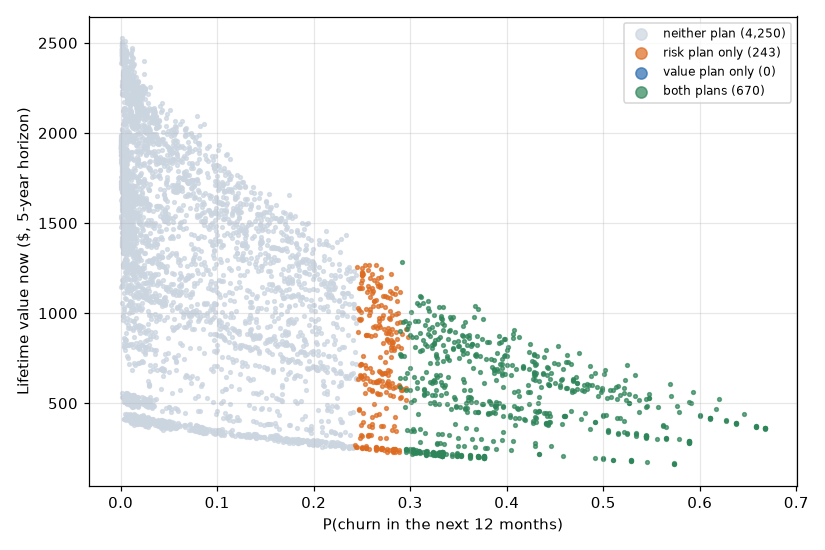

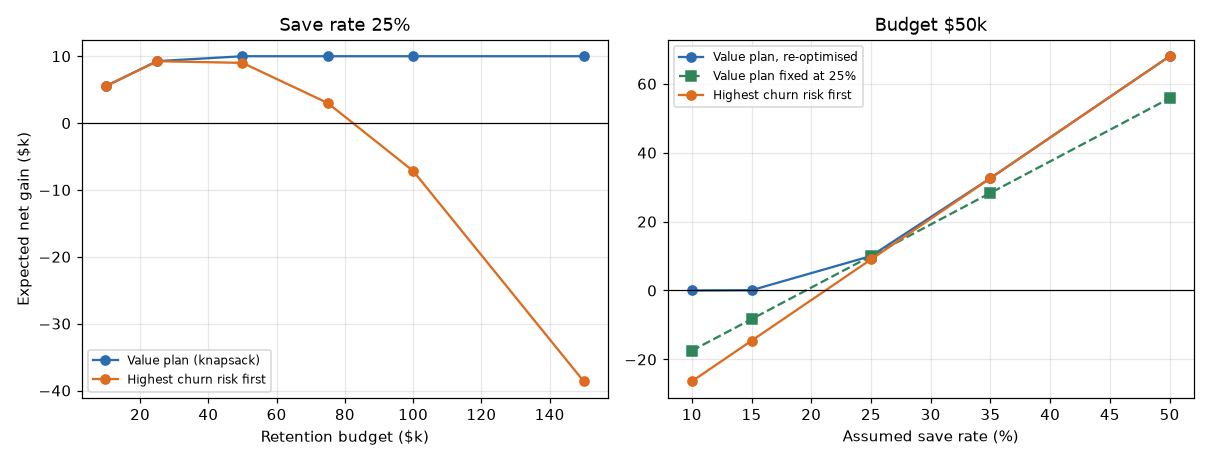

In [11]:
display(Image(str(ROOT / 'results' / 'targeting_map.png')))
display(Image(str(ROOT / 'results' / 'plan_curves.png')))

## 7. Takeaways

- Contract type dominates churn timing; add-on services go with staying.
- The survival models rank as well as a 12-month classifier and, unlike it, give a curve that can be turned into lifetime value.
- With this offer, gain rises with churn risk, so the value plan is the head of the risk list; its benefit is stopping when offers stop paying.
- The save rate is the assumption to test before scaling the budget.